# Handwritten Digit Classification Using a Customized CNN

This CNN uses the MNIST database to classify handwritten digits.


## 1. Import required libraries


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    ReLU,
    MaxPooling2D,
    Flatten,
    Dense,
)
from tensorflow.keras.optimizers import Adam


2026-10-26 07:39:51.524330: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## 2. Load the MNIST database


In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images: ", X_test.shape)
print("Testing labels: ", y_test.shape)


Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images:  (10000, 28, 28)
Testing labels:  (10000,)


## 3. Display handwritten digits


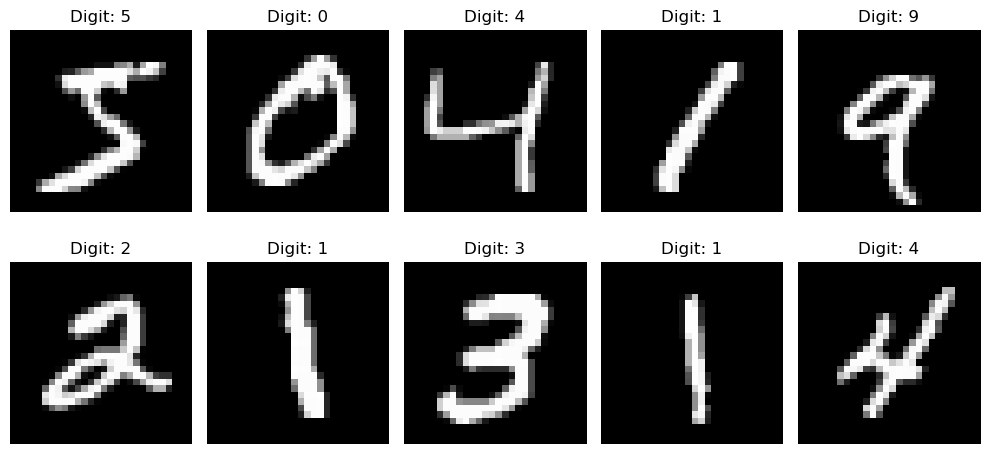

In [3]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


## 4. Prepare the image data


In [4]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training data shape:", X_train.shape)
print("Testing data shape: ", X_test.shape)


Training data shape: (60000, 28, 28, 1)
Testing data shape:  (10000, 28, 28, 1)


## 5. Create the customized CNN

The model has two convolutional layers with 32 and 64 filters. Each convolutional layer is followed by ReLU activation and MaxPooling2D with pool size `(3, 3)` and stride `(1, 1)`.


In [5]:
model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(filters=32, kernel_size=(3, 3)),
    ReLU(),
    MaxPooling2D(pool_size=(3, 3), strides=(1, 1)),

    Conv2D(filters=64, kernel_size=(3, 3)),
    ReLU(),
    MaxPooling2D(pool_size=(3, 3), strides=(1, 1)),

    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax"),
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 22, 22, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,638,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,657,930 (6.32 MB)

 Trainable params: 1,657,930 (6.32 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile and train the CNN


In [6]:
model.compile(optimizer=Adam(),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(X_train, y_train,
                    epochs=10,
                    validation_data=(X_test, y_test))


Epoch 1/10


2026-10-26 07:40:01.139402: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 188160000 exceeds 10% of free system memory.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 162s 85ms/step - accuracy: 0.9635 - loss: 0.1157 - val_accuracy: 0.9797 - val_loss: 0.0608
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 139s 74ms/step - accuracy: 0.9868 - loss: 0.0448 - val_accuracy: 0.9864 - val_loss: 0.0446
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 155s 82ms/step - accuracy: 0.9895 - loss: 0.0329 - val_accuracy: 0.9871 - val_loss: 0.0401
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 194s 78ms/step - accuracy: 0.9920 - loss: 0.0253 - val_accuracy: 0.9858 - val_loss: 0.0434
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 149s 79ms/step - accuracy: 0.9928 - loss: 0.0213 - val_accuracy: 0.9888 - val_loss: 0.0338
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 147s 78ms/step - accuracy: 0.9942 - loss: 0.0171 - val_accuracy: 0.9889 - val_loss: 0.0343
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 147s 78ms/step - accuracy: 0.9956 - loss: 0.0141 - val_accuracy: 0.9900 - val_loss: 0.0375
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 145s 78ms/step - accuracy: 0.9963 - lo

## 7. Compare training accuracy and testing accuracy


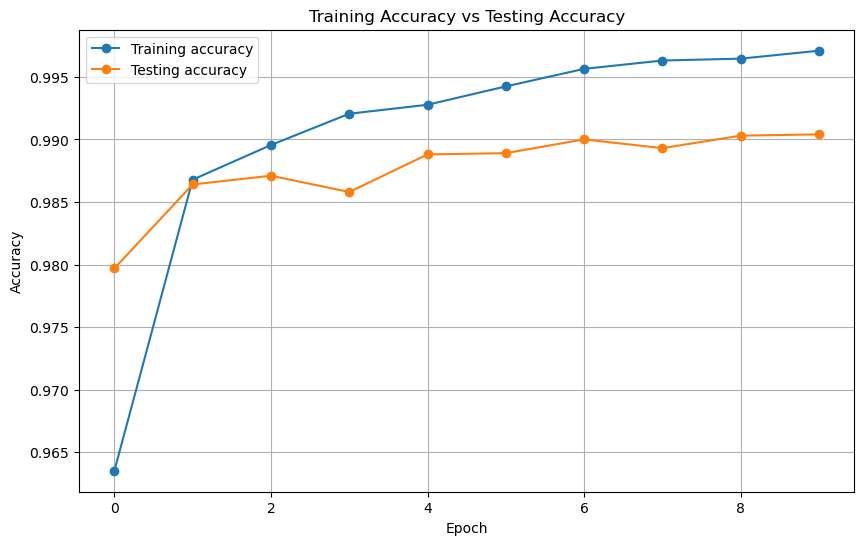

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    history.history["accuracy"],
    label="Training accuracy",
)
plt.plot(
    history.history["val_accuracy"],
    label="Testing accuracy",
)

plt.title("Training Accuracy vs Testing Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()
